# Bildung in Deutschland 2006 bis 2026: Bestand der Tabellen

## Worum es geht

Zu jedem Bericht veröffentlicht der Bildungsbericht Excel-Dateien mit Tabellen und den Daten zu Abbildungen. Bevor `05_indikatoren.ipynb` diese Tabellen mit den Herausforderungen aus dem Text vergleicht, beschreibt dieses Notebook den Bestand: Was liegt für welchen Bericht vor, wie hat sich das Format verändert, und wo gibt es Lücken oder Fehler?

Ein erster Lauf ohne diese Prüfung hat gezeigt, warum sie nötig ist:

- 450 Blätter enthalten die Daten zu Abbildungen und keine Tabellen. Sie hatten keinen lesbaren Titel und zählten trotzdem als Tabellen mit. 2020 waren es 177 von 578 Blättern.
- Die Seiten für 2006 und 2008 verlinken bei A1 und B1 Dateien aus dem Bericht 2010.
- Einige Blätter sind Fortsetzungen einer Tabelle, andere stammen aus fremden Publikationen, etwa der OECD.

## Inhalt dieses Notebooks

| Teil | Abschnitte | Frage |
|---|---|---|
| Daten | 1 bis 2: Grundlagen, Download | Welche Dateien gibt es? |
| Prüfung | 3 bis 5: Kopien, Inhaltsblätter, Blätter | Welche Dateien sind Kopien? Was nennt das Inhaltsblatt, was enthalten die Blätter? |
| Bestand | 6: bereinigter Bestand, Abbildung 12 | Wie viele Tabellen und Abbildungen hat jeder Bericht, und woher stammen sie? |
| Fortschreibung | 7: Abbildung 13 | Welche Tabellen schreibt der Bericht fort, welche sind neu, welche fallen weg? |

## Aufbau der Excel-Dateien

Jede Datei gehört zu einem Indikator, etwa A1 oder C3. Das erste Blatt heißt "Inhalt" und listet alle Tabellen und Abbildungen der Datei mit Nummer und Titel. Jedes weitere Blatt enthält eine Tabelle oder die Daten zu einer Abbildung. Der Aufbau ändert sich über die Jahre:

| Berichte | Aufbau |
|---|---|
| 2006 bis 2018 | Tabellen aus dem Anhang des Buchs (Nummer endet auf "A") und ergänzende Internet-Tabellen (Nummer endet auf "web"). In den frühen Berichten steht der Titel in der ersten Zeile des Blatts, später in der zweiten nach "Zurück zum Inhalt" |
| 2020 | zusätzlich die Daten zu fast allen Abbildungen des Buchs (Nummer ohne Endung) |
| 2022 bis 2026 | nur Internet-Tabellen. Das Inhaltsblatt nennt für jede Tabelle ihre Nummer im Vorgängerbericht |

## Datengrundlage und Textauszüge

Die Excel-Dateien liegen unter `data/raw/tabellen`, das Verzeichnis mit allen Titeln unter `data/interim`. Beide Ordner stehen in der `.gitignore`. Dieses Notebook gibt keine Titel und keine Inhalte der Tabellen aus, nur Nummern und Zählungen.

## Voraussetzungen

- Internetzugang für den ersten Lauf von Abschnitt 2. Liegen die Dateien schon vor, braucht das Notebook keine Verbindung.
- R 4.6.1 mit den Paketen `dplyr`, `tidyr`, `ggplot2`, `stringr`, `purrr`, `readxl`, `rvest` und `xml2`. Die erste Zelle installiert fehlende Pakete.

## Laufzeit

Der erste Download dauert etwa 5 bis 15 Minuten. Das Lesen aller Blätter in Abschnitt 5 dauert einige Minuten. Das Ergebnis speichert das Notebook, jeder weitere Lauf liest es aus der Datei.

### 1. Grundlagen

In [43]:
setwd("C:/Users/c.sezgin/OneDrive - DIPF/Computational Social Sciences/bildungsbericht")
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
pakete <- c("dplyr", "tidyr", "ggplot2", "stringr", "purrr", "readxl", "rvest", "xml2")
for (paket in pakete) {
  if (!requireNamespace(paket, quietly = TRUE)) install.packages(paket)
}
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(stringr)
  library(purrr)
})
dir.create("figures", showWarnings = FALSE)
dir.create("data/raw/tabellen", recursive = TRUE, showWarnings = FALSE)
dir.create("data/interim", recursive = TRUE, showWarnings = FALSE)
dir.create("data/processed", recursive = TRUE, showWarnings = FALSE)

jahre <- seq(2006, 2026, by = 2)
quelle <- "Quelle: Bildung in Deutschland 2006 bis 2026, Excel-Dateien zu den Berichten, eigene Berechnung"

# Lesen eines Blatts als Textmatrix, ohne Meldungen
lies_blatt <- function(pfad, blatt, n_max = Inf) {
  d <- tryCatch(suppressMessages(readxl::read_excel(pfad, sheet = blatt, col_names = FALSE, n_max = n_max,
                                                     col_types = "text", .name_repair = "minimal")),
                error = function(e) NULL)
  if (is.null(d) || nrow(d) == 0) return(NULL)
  trimws(as.matrix(d))
}

# Nummer einer Tabelle oder Abbildung erkennen und vereinheitlichen
muster_nr <- "(?i)^(tab|abb)(?:\\.|elle|ildung)?\\s*([A-I])\\.?\\s?(\\d{1,2}(?:\\.\\d{1,2})?)\\s?[-\u2010\u2011\u2012\u2013\u2014]\\s?(\\d{1,2})\\s?([A-Za-z]*)"
lies_nr <- function(x) {
  m <- str_match(x, muster_nr)
  tibble(art = case_when(is.na(m[, 2]) ~ NA_character_,
                         tolower(m[, 2]) == "tab" ~ "Tabelle",
                         TRUE ~ "Abbildung"),
         nr = if_else(is.na(m[, 2]), NA_character_,
                      paste0(toupper(m[, 3]), m[, 4], "-", m[, 5], tolower(m[, 6]))))
}
herkunft <- function(nr) case_when(is.na(nr) ~ NA_character_,
                                   str_detect(nr, "web$") ~ "Internet",
                                   str_detect(nr, "a$") ~ "Buchanhang",
                                   TRUE ~ "Buchtext")

### 2. Excel-Dateien herunterladen

Für jeden Bericht gibt es auf bildungsbericht.de eine Seite `daten-JAHR` mit Links zu den Excel-Dateien, eine Datei je Indikator. Die Zelle liest die Links von allen elf Seiten und lädt die Dateien nach `data/raw/tabellen/JAHR/`. Dateien, die schon vorhanden sind, lädt sie nicht noch einmal. Die Liste der Links speichert sie unter `data/interim/tabellen_links.csv`. Gibt es diese Datei, liest die Zelle die Links aus ihr.

Den Indikator lese ich aus dem Dateinamen: `c3-2026-webanhang.xlsx` gehört zu Indikator C3. Einige Seiten verlinken Dateien aus dem Ordner eines anderen Berichts. Dafür gilt eine Regel:

- **Link auf einen späteren Bericht:** Das ist ein Fehler der Seite. Die Seiten 2006 und 2008 verlinken etwa `a1-2010.xlsx` und `b1-2010.xlsx`. Diese Dateien gehören zum Bericht 2010 und liegen dort schon. Die Zelle lädt sie nicht.
- **Link auf einen früheren Bericht:** Der Bericht übernimmt die Datei unverändert. Die Seite 2008 verlinkt für A1 die Datei `a1.xlsx` aus dem Ordner 2006. Die Zelle lädt sie in den Ordner 2008.

Dateien, die jemand von Hand in einen Jahresordner gelegt hat, nimmt die Zelle ebenfalls auf und markiert sie als "von Hand ergänzt". Trägt der Dateiname die Jahreszahl eines anderen Berichts, etwa `a1-2010.xlsx` im Ordner 2008, lässt die Zelle sie weg. Ist eine von Hand ergänzte Datei identisch mit einer geladenen Datei desselben Berichts, gilt nur die geladene (Abschnitt 3).

In [44]:
basis <- "https://www.bildungsbericht.de/de/datengrundlagen/daten-"
datei_links <- "data/interim/tabellen_links.csv"

links_jahr <- function(jahr) {
  adresse <- paste0(basis, jahr)
  seite <- rvest::read_html(adresse)
  href <- rvest::html_attr(rvest::html_elements(seite, "a"), "href")
  href <- href[!is.na(href) & grepl("\\.xlsx?$", href, ignore.case = TRUE)]
  tibble(jahr = jahr, url = unique(xml2::url_absolute(href, adresse)))
}

if (file.exists(datei_links)) {
  links <- read.csv(datei_links, fileEncoding = "UTF-8") |> as_tibble()
  cat("Links aus", datei_links, "geladen.\n")
} else {
  links <- map_dfr(jahre, function(j) {
    Sys.sleep(1)
    tryCatch(links_jahr(j), error = function(e) {
      message("Seite ", j, " nicht lesbar: ", conditionMessage(e))
      tibble(jahr = integer(), url = character())
    })
  })
  write.csv(links, datei_links, row.names = FALSE, fileEncoding = "UTF-8")
}

nummer <- str_match(tolower(basename(links$url)), "^([a-i])[-_]?(\\d{1,2})")
links <- links |>
  mutate(jahr = as.integer(jahr),
         datei = basename(url),
         indikator = if_else(is.na(nummer[, 2]), NA_character_, toupper(paste0(nummer[, 2], nummer[, 3]))),
         ordner_jahr = as.integer(str_match(url, "bildungsbericht-(20\\d\\d)/")[, 2]),
         eigener_ordner = is.na(ordner_jahr) | ordner_jahr == jahr)

# Links auf einen späteren Bericht sind Fehler der Seite. Links auf einen früheren Bericht übernimmt der Bericht.
links <- links |> mutate(spaeterer_bericht = !is.na(ordner_jahr) & ordner_jahr > jahr)
fremd <- links |> filter(!is.na(indikator), spaeterer_bericht)
dateien <- links |>
  filter(!is.na(indikator), !spaeterer_bericht) |>
  group_by(jahr, indikator) |>
  filter(if (any(eigener_ordner)) eigener_ordner else TRUE) |>
  ungroup() |>
  distinct(jahr, url, .keep_all = TRUE) |>
  mutate(pfad = file.path("data/raw/tabellen", jahr, datei))

for (i in seq_len(nrow(dateien))) {
  if (file.exists(dateien$pfad[i])) next
  dir.create(dirname(dateien$pfad[i]), recursive = TRUE, showWarnings = FALSE)
  ok <- tryCatch({
    download.file(dateien$url[i], dateien$pfad[i], mode = "wb", quiet = TRUE)
    TRUE
  }, error = function(e) FALSE)
  if (!ok) {
    message("Download fehlgeschlagen: ", dateien$url[i])
    if (file.exists(dateien$pfad[i])) file.remove(dateien$pfad[i])
  }
  Sys.sleep(0.5)
}
dateien$vorhanden <- file.exists(dateien$pfad)
dateien$von_hand <- FALSE

# Von Hand ergänzte Dateien in den Jahresordnern
von_hand <- tibble(pfad = list.files("data/raw/tabellen", pattern = "\\.xlsx?$", recursive = TRUE, full.names = TRUE)) |>
  mutate(jahr = as.integer(basename(dirname(pfad))), datei = basename(pfad)) |>
  filter(jahr %in% jahre, !pfad %in% dateien$pfad) |>
  mutate(jahr_im_namen = as.integer(str_extract(datei, "20\\d\\d"))) |>
  filter(is.na(jahr_im_namen) | jahr_im_namen == jahr) |>
  select(-jahr_im_namen)
nr_hand <- str_match(tolower(von_hand$datei), "^([a-i])[-_]?(\\d{1,2})")
von_hand <- von_hand |>
  mutate(indikator = if_else(is.na(nr_hand[, 2]), NA_character_, toupper(paste0(nr_hand[, 2], nr_hand[, 3]))),
         url = NA_character_, ordner_jahr = jahr, eigener_ordner = TRUE, vorhanden = TRUE, von_hand = TRUE) |>
  filter(!is.na(indikator))
dateien <- bind_rows(dateien, von_hand)

cat("Links insgesamt:", nrow(links), "| ohne erkennbaren Indikator:", sum(is.na(links$indikator)), "\n")
cat("Links auf einen späteren Bericht, nicht geladen:", nrow(fremd), "\n")
if (nrow(fremd)) print(fremd |> select(jahr, indikator, datei, ordner_jahr))
if (any(!dateien$eigener_ordner)) {
  cat("Aus einem früheren Bericht übernommen:\n")
  print(dateien |> filter(!eigener_ordner) |> select(jahr, indikator, datei, ordner_jahr))
}
cat("Dateien ausgewählt:", nrow(dateien), "| aus früherem Bericht:", sum(!dateien$eigener_ordner),
    "| vorhanden:", sum(dateien$vorhanden), "| von Hand ergänzt:", sum(dateien$von_hand), "\n")
if (any(dateien$von_hand)) print(dateien |> filter(von_hand) |> select(jahr, indikator, datei))

Links aus data/interim/tabellen_links.csv geladen.
Links insgesamt: 461 | ohne erkennbaren Indikator: 5 
Links auf einen späteren Bericht, nicht geladen: 4 
# A tibble: 4 × 4
   jahr indikator datei        ordner_jahr
  <int> <chr>     <chr>              <int>
1  2006 A1        a1-2010.xlsx        2010
2  2006 B1        b1-2010.xlsx        2010
3  2008 A1        a1-2010.xlsx        2010
4  2008 B1        b1-2010.xlsx        2010
Aus einem früheren Bericht übernommen:
# A tibble: 1 × 4
   jahr indikator datei   ordner_jahr
  <int> <chr>     <chr>         <int>
1  2008 A1        a1.xlsx        2006
Dateien ausgewählt: 452 | aus früherem Bericht: 1 | vorhanden: 452 | von Hand ergänzt: 0 


**Befund zu Abschnitt 2:** Die elf Seiten enthalten 461 Links auf Excel-Dateien. 5 Links tragen keinen erkennbaren Indikator im Dateinamen und fallen weg. Fünf Links zeigen in den Ordner eines anderen Berichts:

| Seite | Indikator | Datei | aus Ordner | Behandlung |
|---|---|---|---|---|
| 2006 | A1 | a1-2010.xlsx | 2010 | späterer Bericht, nicht geladen |
| 2006 | B1 | b1-2010.xlsx | 2010 | späterer Bericht, nicht geladen |
| 2008 | A1 | a1-2010.xlsx | 2010 | späterer Bericht, nicht geladen |
| 2008 | B1 | b1-2010.xlsx | 2010 | späterer Bericht, nicht geladen |
| 2008 | A1 | a1.xlsx | 2006 | früherer Bericht, übernommen |

Es bleiben 452 Dateien, alle vorhanden. Von Hand ergänzte Dateien gibt es keine.

### 3. Kopien erkennen

Zwei Dateien mit identischem Inhalt haben dieselbe Prüfsumme (MD5). Ich berechne sie für jede Datei. Die Prüfung hat zwei Aufgaben:

1. **Innerhalb eines Berichts:** Ist eine von Hand ergänzte Datei identisch mit einer geladenen Datei desselben Berichts, fällt die von Hand ergänzte weg. Sonst zählen ihre Tabellen doppelt.
2. **Zwischen Berichten:** Identische Dateien in verschiedenen Berichten zeigt die Zelle an. Sie bleiben im Bestand, weil die Seite sie für beide Berichte verlinkt. Bekannt ist ein Fall: Der Bericht 2008 übernimmt für A1 die Datei aus 2006.

In [45]:
dateien <- dateien |>
  filter(vorhanden) |>
  mutate(md5 = unname(tools::md5sum(pfad)))
doppelt_hand <- dateien |>
  group_by(jahr, md5) |>
  filter(von_hand & any(!von_hand)) |>
  ungroup()
cat("Von Hand ergänzte Dateien, identisch mit einer geladenen Datei desselben Berichts:", nrow(doppelt_hand), "\n")
if (nrow(doppelt_hand)) print(doppelt_hand |> select(jahr, indikator, datei))
dateien <- dateien |>
  anti_join(doppelt_hand |> select(pfad), by = "pfad") |>
  group_by(md5) |>
  mutate(jahre_gleich = n_distinct(jahr),
         kopie = FALSE) |>
  ungroup()

cat("Dateien mit identischem Inhalt in mehreren Berichten:", sum(dateien$jahre_gleich > 1), "\n")
cat("\n")
dateien |>
  filter(jahre_gleich > 1) |>
  arrange(md5, jahr) |>
  transmute(gruppe = as.integer(factor(md5)), jahr, indikator, datei, ordner_jahr) |>
  print(n = Inf)

Von Hand ergänzte Dateien, identisch mit einer geladenen Datei desselben Berichts: 0 
Dateien mit identischem Inhalt in mehreren Berichten: 2 

# A tibble: 2 × 5
  gruppe  jahr indikator datei   ordner_jahr
   <int> <int> <chr>     <chr>         <int>
1      1  2006 A1        a1.xlsx        2006
2      1  2008 A1        a1.xlsx        2006


**Befund zu Abschnitt 3:** Nur ein Paar von Dateien ist identisch: A1 in den Berichten 2006 und 2008. Die Seite 2008 verlinkt die Datei aus 2006, der Bericht 2008 übernimmt die beiden Tabellen also unverändert. Beide bleiben im Bestand. Alle anderen Dateien sind verschieden.

### 4. Inhaltsblätter lesen

Das Inhaltsblatt listet jede Tabelle und Abbildung der Datei. Je nach Jahr steht Nummer und Titel in einer Zelle ("Tab. A1-1A: Titel") oder in zwei Zellen. Ab 2022 folgt eine dritte Spalte mit der Nummer im Vorgängerbericht. Ein Strich oder ein weicher Trennstrich in dieser Spalte heißt: Die Tabelle ist neu. Steht dort eine Nummer ohne "Tab." davor oder mitten im Text, etwa "Teile in Tab. G1-1web", erkenne ich sie trotzdem. Ist die Zelle leer oder enthält sie etwas anderes, gilt die Angabe als fehlend ("ohne Angabe") und nicht als neu. Im ersten Lauf zählten solche Fälle als neu. Abschnitt 4 zeigt, wie viele Tabellen das betrifft.

Ich lese aus jedem Inhaltsblatt alle Zeilen, deren erste Zelle mit "Tab" oder "Abb" beginnt, und vereinheitliche die Nummer: Leerzeichen und verschiedene Bindestriche fallen weg, "I.1-5web" wird zu "I1-5web".

In [46]:
lies_inhalt <- function(pfad) {
  blaetter <- tryCatch(readxl::excel_sheets(pfad), error = function(e) character())
  inhalt <- blaetter[grepl("^inhalt", tolower(blaetter))][1]
  if (is.na(inhalt)) return(tibble(inhalt_nr = character()))
  m <- lies_blatt(pfad, inhalt)
  if (is.null(m)) return(tibble(inhalt_nr = character()))
  mit_vorgaenger <- any(grepl("enthalten als", m, ignore.case = TRUE))
  map_dfr(seq_len(nrow(m)), function(i) {
    z <- m[i, !is.na(m[i, ]) & m[i, ] != ""]
    if (length(z) == 0) return(NULL)
    nr <- lies_nr(z[1])
    if (is.na(nr$nr)) return(NULL)
    titel <- if (str_detect(z[1], ":")) str_trim(str_remove(z[1], "^[^:]*:")) else if (length(z) > 1) z[2] else NA_character_
    vorgaenger <- NA_character_
    roh <- NA_character_
    if (mit_vorgaenger) {
      rest <- if (str_detect(z[1], ":")) z[-1] else z[-(1:2)]
      roh <- if (length(rest)) paste(rest, collapse = " | ") else ""
      v <- coalesce(lies_nr(rest)$nr, lies_nr(paste("Tab.", rest))$nr,
                    lies_nr(str_extract(rest, "(?i)(tab|abb)\\.?\\s*[A-I].*"))$nr)
      v <- v[!is.na(v)]
      vorgaenger <- case_when(length(v) > 0 ~ v[1],
                              length(rest) > 0 && all(grepl("^[\u00ad\u2010-\u2014\u2212 -]*$", rest)) ~ "neu",
                              TRUE ~ "ohne Angabe")
    }
    tibble(inhalt_art = nr$art, inhalt_nr = nr$nr, inhalt_titel = titel, vorgaenger = vorgaenger,
           vorgaenger_roh = roh, mit_vorgaenger = mit_vorgaenger)
  })
}

datei_inhalt <- "data/interim/tabellen_inhalt_v2.rds"
gespeichert <- if (file.exists(datei_inhalt)) readRDS(datei_inhalt) else NULL
if (!is.null(gespeichert) && setequal(unique(gespeichert$pfad), dateien$pfad)) {
  inhalt <- gespeichert
  cat("Inhaltsblätter aus", datei_inhalt, "geladen.\n")
} else {
  inhalt <- dateien |>
    select(jahr, indikator, pfad, kopie) |>
    mutate(info = map(pfad, lies_inhalt)) |>
    unnest(info)
  saveRDS(inhalt, datei_inhalt)
}

ohne_inhalt <- setdiff(dateien$pfad, inhalt$pfad)
cat("Dateien ohne lesbares Inhaltsblatt:", length(ohne_inhalt), "\n")
cat("Einträge in den Inhaltsblättern:", nrow(inhalt), "\n\n")
cat("Einträge je Bericht und Art:\n")
print(table(inhalt$jahr, inhalt$inhalt_art))
cat("\nBerichte mit Verweis auf den Vorgängerbericht:",
    paste(sort(unique(inhalt$jahr[!is.na(inhalt$vorgaenger)])), collapse = ", "), "\n\n")
cat("Dateien mit und ohne Spalte zum Vorgängerbericht, ab 2022:\n")
print(inhalt |> filter(jahr >= 2022) |> distinct(jahr, indikator, mit_vorgaenger) |>
        count(jahr, mit_vorgaenger) |> pivot_wider(names_from = mit_vorgaenger, values_from = n, values_fill = 0))
cat("\nAngabe zum Vorgänger je Bericht (nur Tabellen):\n")
print(inhalt |> filter(jahr >= 2022, inhalt_art == "Tabelle") |>
        mutate(angabe = case_when(is.na(vorgaenger) ~ "keine Spalte", vorgaenger %in% c("neu", "ohne Angabe") ~ vorgaenger,
                                  TRUE ~ "Nummer")) |>
        count(jahr, angabe) |> pivot_wider(names_from = angabe, values_from = n, values_fill = 0))
cat("\nHäufigste nicht erkannte Einträge in der Spalte zum Vorgänger:\n")
print(inhalt |> filter(vorgaenger == "ohne Angabe") |> count(vorgaenger_roh, sort = TRUE) |> head(15))

Inhaltsblätter aus data/interim/tabellen_inhalt_v2.rds geladen.
Dateien ohne lesbares Inhaltsblatt: 0 
Einträge in den Inhaltsblättern: 4835 

Einträge je Bericht und Art:
      
       Abbildung Tabelle
  2006        11     219
  2008        25     295
  2010        30     376
  2012        43     455
  2014        35     455
  2016        56     399
  2018        59     412
  2020       176     400
  2022         2     381
  2024         3     469
  2026         6     528

Berichte mit Verweis auf den Vorgängerbericht: 2022, 2024, 2026 

Dateien mit und ohne Spalte zum Vorgängerbericht, ab 2022:
# A tibble: 3 × 3
   jahr `FALSE` `TRUE`
  <int>   <int>  <int>
1  2022       6     38
2  2024       0     44
3  2026       0     44

Angabe zum Vorgänger je Bericht (nur Tabellen):
# A tibble: 3 × 5
   jahr Nummer `keine Spalte`   neu `ohne Angabe`
  <int>  <int>          <int> <int>         <int>
1  2022    154             58   168             1
2  2024    210              0   212          

**Befund zu Abschnitt 4:** Alle 452 Dateien haben ein lesbares Inhaltsblatt mit zusammen 4.835 Einträgen. Die Einträge zu Abbildungen schwanken stark: 2 bis 59 in den meisten Berichten, 176 im Bericht 2020.

Die Spalte zum Vorgängerbericht gibt es ab 2022:

| Bericht | Dateien mit Spalte | Tabellen mit Vorgänger | neu | ohne Angabe |
|---|---|---|---|---|
| 2022 | 38 von 44 | 154 | 168 | 59 (davon 58 in Dateien ohne Spalte) |
| 2024 | 44 von 44 | 210 | 212 | 47 |
| 2026 | 44 von 44 | 231 | 294 | 3 |

Bei den Tabellen ohne Angabe ist die Zelle fast immer leer (49 Fälle). Zweimal steht dort "Tabl." statt "Tab.", ein Tippfehler im Inhaltsblatt. Ob eine leere Zelle "neu" bedeutet, lässt sich nicht sicher sagen. Deshalb zählen diese Tabellen getrennt.

### 5. Blätter lesen und einordnen

Für jedes Blatt außer dem Inhaltsblatt lese ich die ersten acht Zeilen und suche die Zelle, die mit "Tab" oder "Abb" beginnt. Sie enthält Nummer und Titel. Im ersten Lauf hat das Notebook nur nach "Tab" gesucht. Abbildungen erhielten deshalb als Titel "Zurück zum Inhalt".

Jedes Blatt erhält eine Einordnung:

| Einordnung | Erkennungsmerkmal |
|---|---|
| Tabelle | Titel beginnt mit "Tab" und einer Nummer |
| Abbildung | Titel beginnt mit "Abb" und einer Nummer |
| | Fehlt die Nummer im Titel, lese ich sie aus dem Namen des Blatts, etwa "Abb. A1-2A" |
| Fortsetzung | Name des Blatts beginnt mit "Forts", die Tabelle steht schon auf einem anderen Blatt |
| Sonstiges | keine Nummer im Titel, etwa Blätter aus OECD-Publikationen oder mit Makros |

Manche Blätter enthalten nur den Link "Zurück zum Inhalt" und keine Daten, etwa bei Abbildungen, die das Buch als Grafik zeigt. Ich markiere Blätter mit höchstens zwei Zeilen als "ohne Daten".

Danach gleiche ich die Blätter mit den Inhaltsblättern ab. Ein Blatt ohne Eintrag im Inhaltsblatt oder ein Eintrag ohne Blatt deutet auf eine Lücke.

In [47]:
lies_blaetter <- function(pfad) {
  blaetter <- tryCatch(readxl::excel_sheets(pfad), error = function(e) character())
  blaetter <- blaetter[!grepl("^inhalt", tolower(blaetter))]
  map_dfr(blaetter, function(blatt) {
    m_ganz <- lies_blatt(pfad, blatt, n_max = 12)
    zeilen <- if (is.null(m_ganz)) 0L else nrow(m_ganz)
    m <- if (is.null(m_ganz)) NULL else m_ganz[seq_len(min(8, zeilen)), , drop = FALSE]
    zellen <- if (is.null(m)) character() else as.vector(t(m))
    zellen <- zellen[!is.na(zellen) & zellen != ""]
    pos <- which(!is.na(lies_nr(zellen)$nr))[1]
    if (is.na(pos)) {
      return(tibble(blatt = blatt, titel = if (length(zellen)) zellen[1] else NA_character_, zeilen = zeilen))
    }
    titel <- zellen[pos]
    if (!str_detect(titel, ":") && pos < length(zellen)) titel <- paste(titel, zellen[pos + 1])
    tibble(blatt = blatt, titel = titel, zeilen = zeilen)
  })
}

datei_blaetter <- "data/interim/tabellen_blaetter.rds"
gespeichert <- if (file.exists(datei_blaetter)) readRDS(datei_blaetter) else NULL
if (!is.null(gespeichert) && setequal(unique(gespeichert$pfad), dateien$pfad)) {
  blaetter <- gespeichert
  cat("Blätter aus", datei_blaetter, "geladen.\n")
} else {
  blaetter <- dateien |>
    select(jahr, indikator, pfad, datei, kopie) |>
    mutate(info = map(pfad, lies_blaetter)) |>
    unnest(info)
  saveRDS(blaetter, datei_blaetter)
}

nr_titel <- lies_nr(blaetter$titel)
nr_name <- lies_nr(blaetter$blatt)
blaetter <- blaetter |>
  mutate(art = coalesce(nr_titel$art, nr_name$art),
         nr = coalesce(nr_titel$nr, nr_name$nr),
         nr_aus_name = is.na(nr_titel$nr) & !is.na(nr_name$nr),
         ohne_daten = zeilen <= 2) |>
  mutate(einordnung = case_when(grepl("^forts", tolower(blatt)) ~ "Fortsetzung",
                                !is.na(art) ~ art,
                                TRUE ~ "Sonstiges"),
         herkunft = herkunft(nr),
         titel = str_trim(str_remove(titel, "^[^:]*:")))

cat("Blätter insgesamt:", nrow(blaetter), "\n")
cat("Nummer nur aus dem Blattnamen erkannt:", sum(blaetter$nr_aus_name), "\n")
cat("Blätter ohne Daten (höchstens zwei Zeilen):", sum(blaetter$ohne_daten),
    "| davon Tabellen:", sum(blaetter$ohne_daten & blaetter$einordnung == "Tabelle"), "\n\n")
cat("Einordnung je Bericht:\n")
print(table(blaetter$jahr, blaetter$einordnung))

abgleich <- full_join(
  blaetter |> filter(!kopie, einordnung %in% c("Tabelle", "Abbildung")) |> distinct(jahr, indikator, art, nr) |> mutate(blatt_da = TRUE),
  inhalt |> filter(!kopie) |> distinct(jahr, indikator, art = inhalt_art, nr = inhalt_nr) |> mutate(inhalt_da = TRUE),
  by = c("jahr", "indikator", "art", "nr"))
cat("\nBlätter ohne Eintrag im Inhaltsblatt:", sum(is.na(abgleich$inhalt_da)), "\n")
cat("Einträge im Inhaltsblatt ohne Blatt:", sum(is.na(abgleich$blatt_da)), "\n")
print(abgleich |> filter(is.na(inhalt_da) | is.na(blatt_da)) |>
        count(jahr, fehlt = if_else(is.na(inhalt_da), "im Inhaltsblatt", "als Blatt")) |>
        pivot_wider(names_from = fehlt, values_from = n, values_fill = 0))

Blätter aus data/interim/tabellen_blaetter.rds geladen.
Blätter insgesamt: 4891 
Nummer nur aus dem Blattnamen erkannt: 124 
Blätter ohne Daten (höchstens zwei Zeilen): 441 | davon Tabellen: 0 

Einordnung je Bericht:
      
       Abbildung Fortsetzung Sonstiges Tabelle
  2006        11           0         4     219
  2008        25           5         0     295
  2010        30           0         0     376
  2012        43           0         2     455
  2014        38           0        22     456
  2016        56           0         0     402
  2018        61           0         0     422
  2020       178           0         0     400
  2022         3           0         0     382
  2024         3           0         0     469
  2026         6           0         0     528

Blätter ohne Eintrag im Inhaltsblatt: 37 
Einträge im Inhaltsblatt ohne Blatt: 22 
# A tibble: 9 × 3
   jahr `als Blatt` `im Inhaltsblatt`
  <int>       <int>             <int>
1  2010           1              

**Befund zu Abschnitt 5:** Die 4.891 Blätter ordnen sich so ein: 4.404 Tabellen, 454 Abbildungen, 5 Fortsetzungen und 28 sonstige Blätter. Die sonstigen Blätter sind 22 Blätter einer OECD-Publikation im Bericht 2014, 4 Blätter 2006 und 2 Blätter 2012.

- Bei 124 Blättern steht die Nummer nur im Namen des Blatts, nicht im Titel.
- 441 Blätter enthalten keine Daten, nur den Link zurück zum Inhalt. Alle sind Abbildungen, keine Tabelle ist betroffen.
- Blätter und Inhaltsblätter stimmen weitgehend überein: 37 Blätter fehlen im Inhaltsblatt, 22 Einträge im Inhaltsblatt haben kein Blatt. Die meisten Fälle hat der Bericht 2018 mit 13 Einträgen ohne Blatt. Bei rund 4.900 Blättern sind das jeweils weniger als ein Prozent.

### 6. Bereinigter Bestand

Der Bestand enthält jede Tabelle und jede Abbildung einmal. Es fallen weg:

- von Hand ergänzte Dateien, die eine geladene Datei doppeln (Abschnitt 3)
- Fortsetzungen und sonstige Blätter (Abschnitt 5)
- doppelte Nummern innerhalb eines Berichts, etwa wenn dieselbe Tabelle in zwei Dateien steht

Fehlt der Titel auf dem Blatt, übernehme ich den Titel aus dem Inhaltsblatt. Aus dem Inhaltsblatt übernehme ich auch den Verweis auf den Vorgängerbericht.

Den Bestand mit Titeln speichere ich unter `data/interim/tabellenbestand.rds`. `05_indikatoren.ipynb` liest diese Datei. Die Zählungen ohne Titel speichere ich unter `data/processed/tabellenbestand_zaehlung.csv`.

#### Abbildung 12: Tabellen und Abbildungen je Bericht

Jeder Balken ist ein Bericht. Die Farben trennen Tabellen und Abbildungen und zeigen, woher sie stammen: aus dem Anhang des Buchs, aus dem Text des Buchs oder nur aus dem Internet.

Entfallene Blätter je Bericht:
# A tibble: 4 × 3
   jahr Sonstiges Fortsetzung
  <int>     <int>       <int>
1  2006         4           0
2  2008         0           5
3  2012         2           0
4  2014        22           0

Bestand je Bericht:
# A tibble: 11 × 4
    jahr Abbildung Tabelle Tabelle_ohne_Titel
   <int>     <int>   <int>              <int>
 1  2006        11     219                  0
 2  2008        25     295                  0
 3  2010        29     376                  0
 4  2012        43     455                  0
 5  2014        37     456                  2
 6  2016        55     400                  0
 7  2018        61     421                  0
 8  2020       176     399                  0
 9  2022         3     381                  0
10  2024         3     468                  0
11  2026         6     527                  0


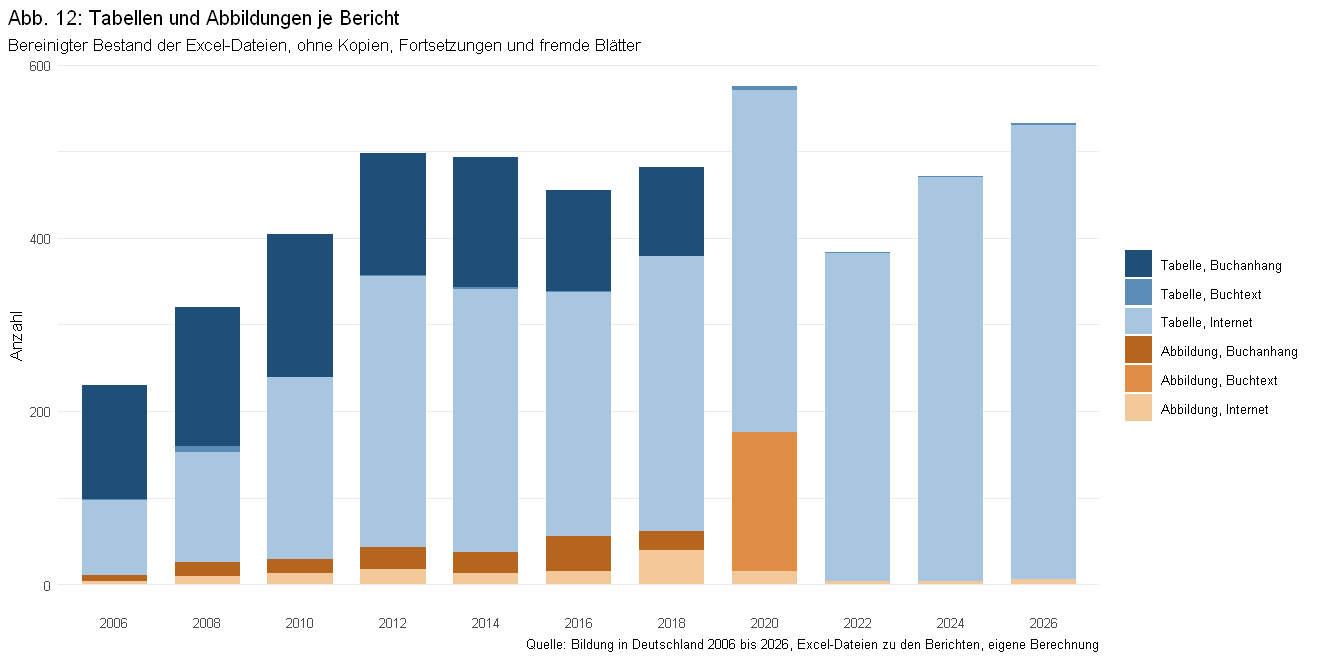

In [48]:
options(repr.plot.width = 11, repr.plot.height = 5.5)

bestand <- blaetter |>
  filter(!kopie, einordnung %in% c("Tabelle", "Abbildung")) |>
  distinct(jahr, art, nr, .keep_all = TRUE) |>
  left_join(inhalt |> distinct(jahr, art = inhalt_art, nr = inhalt_nr, .keep_all = TRUE) |>
              select(jahr, art, nr, inhalt_titel, vorgaenger),
            by = c("jahr", "art", "nr")) |>
  mutate(titel = if_else(is.na(titel) | titel == "" | grepl("^zurück zum inhalt", tolower(titel)), inhalt_titel, titel),
         kapitel = substr(indikator, 1, 1),
         kapitelgruppe = if_else(kapitel == "H", "Schwerpunkt H", "Kernkapitel"),
         tab_nr = nr) |>
  select(jahr, indikator, kapitel, kapitelgruppe, art, herkunft, tab_nr, blatt, titel, vorgaenger, ohne_daten, pfad, datei)
saveRDS(bestand, "data/interim/tabellenbestand.rds")

zaehlung <- bestand |>
  count(jahr, art, herkunft, kapitelgruppe, name = "anzahl")
write.csv(zaehlung, "data/processed/tabellenbestand_zaehlung.csv", row.names = FALSE, fileEncoding = "UTF-8")

entfallen <- blaetter |>
  mutate(grund = case_when(kopie ~ "Kopie",
                           einordnung %in% c("Fortsetzung", "Sonstiges") ~ einordnung,
                           TRUE ~ NA_character_)) |>
  filter(!is.na(grund)) |>
  count(jahr, grund) |>
  pivot_wider(names_from = grund, values_from = n, values_fill = 0)
cat("Entfallene Blätter je Bericht:\n")
print(entfallen)
cat("\nBestand je Bericht:\n")
print(bestand |> count(jahr, art) |> pivot_wider(names_from = art, values_from = n, values_fill = 0) |>
        mutate(Tabelle_ohne_Titel = map_int(jahr, \(j) sum(bestand$jahr == j & bestand$art == "Tabelle" & is.na(bestand$titel)))))

abb12_daten <- bestand |>
  count(jahr, art, herkunft) |>
  mutate(gruppe = factor(paste(art, herkunft, sep = ", "),
                         levels = c("Tabelle, Buchanhang", "Tabelle, Buchtext", "Tabelle, Internet",
                                    "Abbildung, Buchanhang", "Abbildung, Buchtext", "Abbildung, Internet")))

abb12 <- ggplot(abb12_daten, aes(factor(jahr), n, fill = gruppe)) +
  geom_col(width = 0.7) +
  scale_fill_manual(values = c("Tabelle, Buchanhang" = "#1f4e79", "Tabelle, Buchtext" = "#5b8db8",
                               "Tabelle, Internet" = "#a9c6e0", "Abbildung, Buchanhang" = "#b5651d",
                               "Abbildung, Buchtext" = "#e08e45", "Abbildung, Internet" = "#f3c99a"),
                    drop = FALSE, name = NULL) +
  labs(x = NULL, y = "Anzahl",
       title = "Abb. 12: Tabellen und Abbildungen je Bericht",
       subtitle = "Bereinigter Bestand der Excel-Dateien, ohne Kopien, Fortsetzungen und fremde Blätter",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "right", plot.title.position = "plot", panel.grid.major.x = element_blank())

ggsave("figures/abb12_tabellenbestand.png", abb12, width = 11, height = 5.5, dpi = 300, bg = "white")
abb12

**Befund zu Abbildung 12:** Der bereinigte Bestand umfasst 4.397 Tabellen und 449 Abbildungen.

| Bericht | 2006 | 2008 | 2010 | 2012 | 2014 | 2016 | 2018 | 2020 | 2022 | 2024 | 2026 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Tabellen | 219 | 295 | 376 | 455 | 456 | 400 | 421 | 399 | 381 | 468 | 527 |
| Abbildungen | 11 | 25 | 29 | 43 | 37 | 55 | 61 | 176 | 3 | 3 | 6 |

Drei Beobachtungen:

1. **Die Zahl der Tabellen wächst.** Von 219 (2006) auf 527 (2026). Bis 2012 verdoppelt sie sich, danach schwankt sie zwischen 381 und 468 und erreicht 2026 den Höchstwert.
2. **Das Format wechselt 2020.** Bis 2018 stehen in jedem Bericht rund 100 bis 165 Tabellen im Anhang des Buchs, die übrigen nur im Internet. Ab 2020 erscheinen alle Tabellen nur noch im Internet.
3. **2020 ist ein Sonderfall bei den Abbildungen.** Nur in diesem Jahr gibt es die Daten zu fast allen Abbildungen des Buchs (176). Danach fehlen sie fast ganz. Wer Tabellen und Abbildungen zusammen zählt, sieht 2020 einen Ausschlag, der nur am Format liegt. `05_indikatoren.ipynb` zählt deshalb nur Tabellen.

### 7. Fortschreibung der Tabellen

Ab 2022 nennt das Inhaltsblatt für jede Tabelle ihre Nummer im Vorgängerbericht. Damit lässt sich für drei Übergänge zählen:

- **fortgeschrieben:** Die Tabelle hat einen Vorgänger.
- **neu:** Die Tabelle hat keinen Vorgänger.
- **weggefallen:** Eine Tabelle des Vorgängerberichts taucht im neuen Bericht nicht als Vorgänger auf.
- **ohne Angabe:** Das Inhaltsblatt hat keine Spalte zum Vorgänger, oder der Eintrag ist nicht lesbar. Diese Tabellen können fortgeschrieben oder neu sein. Je mehr Tabellen ohne Angabe sind, desto stärker ist die Zahl der weggefallenen Tabellen überschätzt.

Für die Berichte vor 2022 fehlt diese Angabe. Gleiche Nummern in zwei Berichten bedeuten dort nicht, dass es dieselbe Tabelle ist, weil die Nummern innerhalb eines Indikators wechseln.

#### Abbildung 13: Fortgeschriebene, neue und weggefallene Tabellen

Jedes Feld ist ein Übergang zwischen zwei Berichten, jede Zeile ein Kapitel. Die Balken nach rechts zeigen die Tabellen des neuen Berichts, aufgeteilt in fortgeschrieben und neu. Der Balken nach links zeigt die weggefallenen Tabellen des Vorgängerberichts.

# A tibble: 3 × 5
  uebergang    fortgeschrieben   neu `ohne Angabe` weggefallen
  <chr>                  <int> <int>         <int>       <int>
1 2020 zu 2022             154   166            61         248
2 2022 zu 2024             210   210            48         182
3 2024 zu 2026             230   290             7         241


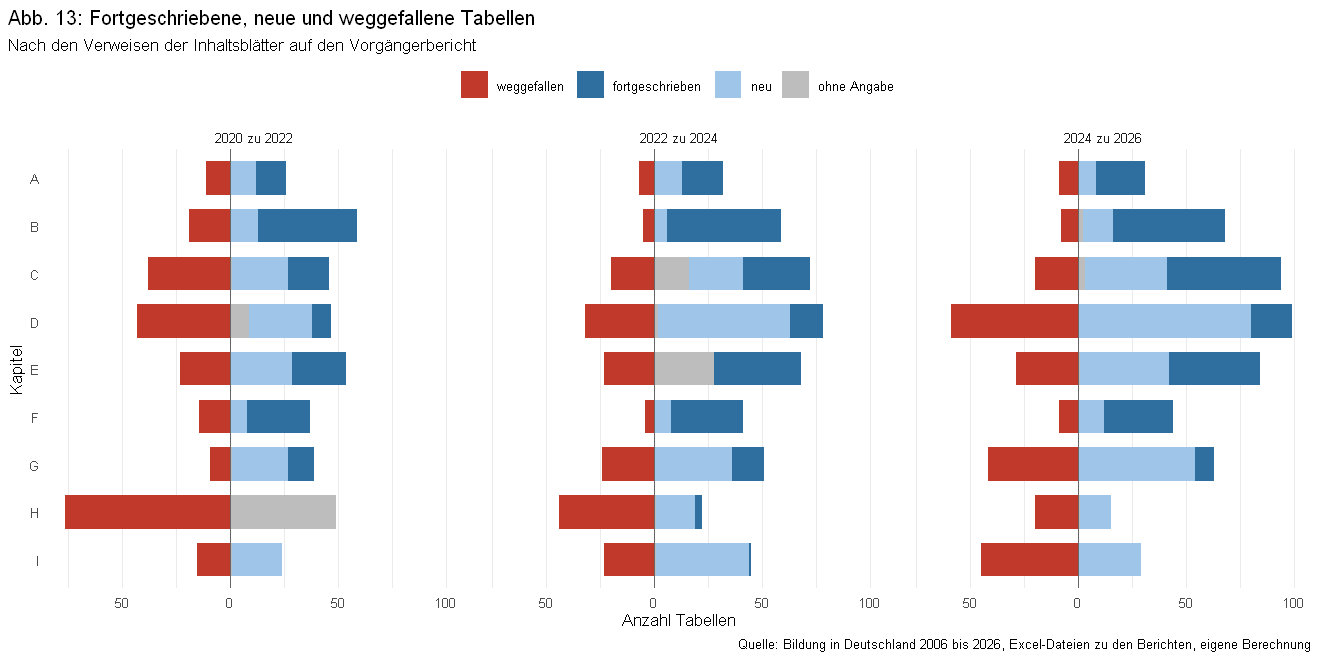

In [49]:
options(repr.plot.width = 11, repr.plot.height = 5.5)

tabellen <- bestand |> filter(art == "Tabelle")
mit_verweis <- sort(unique(tabellen$jahr[!is.na(tabellen$vorgaenger)]))

fortschreibung <- map_dfr(mit_verweis, function(j) {
  neu_bericht <- tabellen |> filter(jahr == j)
  alt_bericht <- tabellen |> filter(jahr == j - 2)
  bind_rows(
    neu_bericht |> transmute(kapitel, status = case_when(is.na(vorgaenger) | vorgaenger == "ohne Angabe" ~ "ohne Angabe",
                                                         vorgaenger == "neu" ~ "neu",
                                                         TRUE ~ "fortgeschrieben")),
    alt_bericht |> filter(!tab_nr %in% neu_bericht$vorgaenger) |> transmute(kapitel, status = "weggefallen")
  ) |>
    mutate(uebergang = paste(j - 2, "zu", j))
})

uebersicht <- fortschreibung |>
  count(uebergang, status) |>
  pivot_wider(names_from = status, values_from = n, values_fill = 0)
write.csv(fortschreibung |> count(uebergang, kapitel, status, name = "anzahl"),
          "data/processed/tabellen_fortschreibung.csv", row.names = FALSE, fileEncoding = "UTF-8")
print(uebersicht)

abb13_daten <- fortschreibung |>
  count(uebergang, kapitel, status) |>
  mutate(n = if_else(status == "weggefallen", -n, n),
         status = factor(status, levels = c("weggefallen", "fortgeschrieben", "neu", "ohne Angabe")))

abb13 <- ggplot(abb13_daten, aes(n, factor(kapitel, levels = rev(LETTERS[1:9])), fill = status)) +
  geom_col(width = 0.7) +
  geom_vline(xintercept = 0, colour = "grey40") +
  facet_wrap(~ uebergang) +
  scale_fill_manual(values = c(weggefallen = "#c0392b", fortgeschrieben = "#2f6f9f", neu = "#9fc5e8",
                               "ohne Angabe" = "#bdbdbd"), drop = FALSE, name = NULL) +
  scale_x_continuous(labels = abs) +
  labs(x = "Anzahl Tabellen", y = "Kapitel",
       title = "Abb. 13: Fortgeschriebene, neue und weggefallene Tabellen",
       subtitle = "Nach den Verweisen der Inhaltsblätter auf den Vorgängerbericht",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "top", plot.title.position = "plot", panel.grid.major.y = element_blank())

ggsave("figures/abb13_fortschreibung.png", abb13, width = 11, height = 5.5, dpi = 300, bg = "white")
abb13

**Befund zu Abbildung 13:** Der Bericht tauscht bei jeder Ausgabe rund die Hälfte seiner Tabellen aus.

| Übergang | fortgeschrieben | neu | ohne Angabe | weggefallen |
|---|---|---|---|---|
| 2020 zu 2022 | 154 | 166 | 61 | 248 |
| 2022 zu 2024 | 210 | 210 | 48 | 182 |
| 2024 zu 2026 | 230 | 290 | 7 | 241 |

Von den Tabellen mit Angabe sind 44 bis 50 Prozent fortgeschrieben, der Rest ist neu. Von den 468 Tabellen des Berichts 2024 tauchen 241 im Bericht 2026 nicht mehr als Vorgänger auf, also gut die Hälfte. Die Tabellen ohne Angabe ändern das Bild kaum: 2026 sind es nur 7.

Die Kapitel unterscheiden sich deutlich:

- **Überwiegend fortgeschrieben:** B (Grundinformationen) und F (Hochschule). Hier bleibt der Kern der Tabellen von Bericht zu Bericht erhalten.
- **Überwiegend neu:** D (Schule), G (Weiterbildung) und I. Im Kapitel D sind 2026 rund 80 Tabellen neu und knapp 20 fortgeschrieben. Kapitel I schreibt fast keine Tabelle fort.
- **Erwartbar neu:** H, das Schwerpunktkapitel. Es wechselt mit jedem Bericht das Thema.

Für die Indikatoren heißt das: Eine Zeitreihe über mehrere Berichte entsteht im Bericht nur bei einem Teil der Tabellen. Wer eine Kennzahl über 20 Jahre verfolgen will, findet sie oft nur, weil eine einzelne Tabelle eine lange Reihe enthält, nicht weil der Bericht dieselbe Tabelle fortschreibt.

## Zusammenfassung

### Ziel

Dieses Notebook beschreibt den Bestand der Excel-Dateien zu den elf Berichten und bereinigt ihn für `05_indikatoren.ipynb`.

### Entscheidungen und Gründe

| Schritt | Entscheidung | Grund |
|---|---|---|
| Fremde Links | Links auf spätere Berichte nicht laden, Links auf frühere Berichte übernehmen | Die Seiten 2006 und 2008 verlinken Dateien von 2010. Ein späterer Bericht kann nicht Quelle eines früheren sein |
| Kopien | identische Dateien über die Prüfsumme erkennen, doppelte Dateien innerhalb eines Berichts entfernen | Von Hand ergänzte Dateien sollen nicht doppelt zählen |
| Einordnung | Tabelle, Abbildung, Fortsetzung, Sonstiges nach Titel und Blattname | Abbildungen, Fortsetzungen und fremde Blätter sind keine eigenen Tabellen des Berichts |
| Titel | vom Blatt, sonst aus dem Inhaltsblatt | Das Inhaltsblatt nennt jede Tabelle, auch wenn das Blatt anders aufgebaut ist |
| Nummern | vereinheitlicht (Bindestriche, Leerzeichen, "I.1" zu "I1") | Dieselbe Tabelle soll dieselbe Nummer tragen |
| Fortschreibung | nur ab 2022 über die Verweise im Inhaltsblatt | Vorher fehlt die Angabe, gleiche Nummern bedeuten nicht gleiche Tabellen |

### Zentrale Befunde

1. **Der Bestand ist gut dokumentiert.** Jede Datei hat ein Inhaltsblatt, Blätter und Einträge stimmen zu über 99 Prozent überein.
2. **Es gibt wenige Fehler in der Veröffentlichung.** Die Seiten 2006 und 2008 verlinken vier Dateien aus dem Bericht 2010. Zwei Verweise auf den Vorgängerbericht enthalten Tippfehler, 49 sind leer.
3. **Das Format wechselt 2020.** Bis 2018 Anhang im Buch und Tabellen im Internet, ab 2020 nur Internet. 2020 kommen einmalig die Daten zu fast allen Abbildungen hinzu.
4. **Die Zahl der Tabellen wächst** von 219 (2006) auf 527 (2026).
5. **Der Bericht tauscht bei jeder Ausgabe rund die Hälfte seiner Tabellen aus.** Fortgeschrieben werden vor allem die Grundinformationen und die Hochschule, ausgetauscht vor allem Schule, Weiterbildung und Kapitel I.

### Grenzen

- Das Notebook erkennt Kopien nur, wenn die Dateien vollständig identisch sind.
- Die Fortschreibung lässt sich nur für 2022 bis 2026 messen. Für die früheren Berichte fehlen die Verweise.
- Eine leere Zelle in der Spalte zum Vorgänger zählt als "ohne Angabe". Bedeutet sie "neu", ist die Zahl der neuen Tabellen 2022 und 2024 etwas höher.
- Die Herkunft einer Tabelle lese ich aus der Endung der Nummer ("A", "web" oder keine). Abweichende Nummern ordnet das Notebook keiner Herkunft zu.